# From Notebook to Production

### Notebook 02 — Data contracts, versioning, serving and monitoring
**Telco customer churn** · ships the logistic regression that notebook 01 evaluated

---

Notebook 01 evaluated the model itself: which model to ship, whether its
explanations and probabilities hold up, and what threshold the economics
support. This notebook asks the other half of the question. A model is
**deployed** when:

- a malformed record cannot reach it
- its preprocessing travels with it, not in a notebook cell someone can edit
- the exact artefact that was approved is the one serving traffic
- someone watching can tell, within a day, that the world has changed
- the previous *approved* version can be restored in under a minute

None of that is modelling. All of it is the majority of the work.

The threshold, temperature and economics come **from notebook 01 through a file**
(`artifacts/decision.json`), so nothing is re-typed here. Run notebook 01 first.

---
### What this notebook does

| § | Layer | Concrete artefact, and the demonstration that it works |
|---|---|---|
| 1 | Ingestion | one data contract with a *training* and a *serving* mode; quarantine records **why** each row was rejected |
| 2 | Features | preprocessing serialised with the model; the serving schema needs no label |
| 3 | Training | a **quality gate** evaluated against real candidates and a trivial baseline |
| 4 | Registry | the whole serving bundle registered with a checksum, held-out metrics kept apart from selection metrics, a model card built from evidence; the gate **blocks** a real weak version |
| 5 | Serving | the bundle loaded **back from the registry**; contract enforced at the boundary; a latency benchmark that scores exactly the rows it reports |
| 6 | Monitoring | drift detection on *internally consistent* simulated traffic, with the data contract catching an inconsistent simulation |
| 7 | Rollback | a successor that passes the gate but is measurably worse, then a byte-exact rollback to the previously **promoted** version |
| 8 | Tests | the suite, run and counted |
| 9 | Conclusions | assembled by code from the results above |

**Deliberately honest scoping.** This is a *simulated* production: the "live"
traffic is a held-out batch we perturb on purpose. No server, no queue, no
feature store, no real customers. What is real is every artefact and every
control, and those are the parts that transfer.

In [1]:
import json
import os
import shutil
import sys
import tempfile
import warnings
from pathlib import Path

os.environ.setdefault("TQDM_DISABLE", "1")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Inline under a kernel, headless otherwise -- see notebook 01 for why this
# detection uses get_ipython() rather than probing sys.modules.
try:
    _in_kernel = get_ipython() is not None      # noqa: F821  (IPython builtin)
except NameError:
    _in_kernel = False
matplotlib.use("module://matplotlib_inline.backend_inline" if _in_kernel else "Agg")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import churnml
from churnml import evaluate as ev
from churnml.pipeline import ChurnScorer, detect_drift
from churnml.registry import next_version, sha256_file

warnings.filterwarnings("ignore")

SEED = churnml.SEED
PATHS = churnml.PATHS.ensure()
PATHS.figures.mkdir(parents=True, exist_ok=True)
NON_INPUT = ["customerID", "Churn", "_target", "_row_id"]

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# This notebook owns its own registry namespace, so re-running it never
# interleaves with anything else. The registry is append-only in production
# (versions are never overwritten) but a notebook must be re-runnable, so it
# starts from an empty one; section 7 still shows genuine version accumulation
# *within* the run.
PROD_VERSIONS = PATHS.artifacts / "prod_versions"
if PROD_VERSIONS.exists():
    shutil.rmtree(PROD_VERSIONS)
PROD_VERSIONS.mkdir(parents=True, exist_ok=True)

# The decision made in notebook 01 (threshold, temperature, economics). Read,
# never re-typed: a threshold typed into two notebooks is two thresholds.
DECISION_FILE = PATHS.artifacts / "decision.json"
if not DECISION_FILE.exists():
    raise FileNotFoundError(f"{DECISION_FILE} not found. Run notebook 01 first: it derives the threshold and temperature shipped here.")
decision = json.loads(DECISION_FILE.read_text(encoding="utf-8"))
THRESHOLD, TEMPERATURE, ECON = decision["threshold"], decision["temperature"], decision["economics"]

print(f"root           : {ROOT}")
print(f"registry       : {PROD_VERSIONS.relative_to(ROOT)}")
print(f"churnml        : {churnml.__version__}")
print(f"decision from notebook 01: model={decision['model']}, threshold={THRESHOLD:.2f}, temperature={TEMPERATURE:.2f}, selected on {decision['selected_on']}")

root           : C:\Users\guerr\OneDrive\Desktop\class\churn-ml-showcase
registry       : artifacts\prod_versions
churnml        : 1.1.0
decision from notebook 01: model=logreg, threshold=0.31, temperature=1.00, selected on validation


---
## 1 · Ingestion: the boundary is where models die

A notebook reads a CSV that is already correct. Production reads a file, an API
response or a message queue, and must decide what to do when it is not.

Three behaviours, and the third is the one people skip:

1. **Reject**: raise and refuse the batch.
2. **Accept silently**: dangerous. Bad data flows into scores that are then
   reported with confidence.
3. **Quarantine and continue**: bad rows are set aside **with a reason**, the
   good rows are processed, and the count of failures raises an alert.

One contract serves both ends. `validate_dataframe(..., mode="training")`
demands the full 21-column frame; `mode="serving"` is the same checks for a
*scoring* batch, where the label and the customer identifier are optional (a
customer who has not churned yet has no label).

In [2]:
dataset, splits, clean_log = churnml.load_and_prepare()

print(f"dataset accepted: {dataset.n_rows:,} rows")
print(f"contract status : {dataset.report.n_errors} error(s), {dataset.report.n_warnings} warning(s)")
print()
print(dataset.report)

dataset accepted: 7,043 rows
contract status : 0 error(s), 1 warning(s)

ValidationReport: 0 error(s), 1 warning(s)
[PASS] schema.columns: all 21 required columns present
[PASS] id.uniqueness: customerID unique
[PASS] nulls.count: no nulls in any column
[PASS] domain.categorical: all categorical values in domain
[PASS] range.numeric: all numeric values within range
[PASS] consistency.addons_without_internet: add-on flags consistent with InternetService
[PASS] consistency.total_vs_tenure: TotalCharges consistent with tenure x MonthlyCharges
[WARN] coercion.TotalCharges: 11 non-numeric cell(s) (blank strings) coerced to NaN (11 rows)


In [3]:
# Prove the quarantine path actually works by corrupting the data the way a
# real feed breaks: a renamed category, a duplicated customer, a bad value.
raw = churnml.load_raw()

corrupt = pd.concat([raw, raw.head(4)], ignore_index=True)   # duplicate IDs
corrupt.loc[5:8, "Contract"] = "Fortnightly"                  # unknown category
corrupt.loc[9, "tenure"] = -3                                 # impossible value

report = churnml.validate_dataframe(corrupt, quarantine_bad=True)
print(report)
print()
print(f"rows in           : {len(corrupt):,}")
print(f"rows quarantined  : {len(report.quarantine):,}")
print(f"rows good         : {len(corrupt) - len(report.quarantine):,}")
print()
print("Quarantined rows, each with the check that rejected it:")
display(report.quarantine[["customerID", "Contract", "tenure", "quarantine_reason"]].reset_index(drop=True))

ValidationReport: 3 error(s), 1 warning(s)
[PASS] schema.columns: all 21 required columns present
[FAIL] id.uniqueness: customerID is not unique; 4 duplicate row(s) (4 rows)
[PASS] nulls.count: no nulls in any column
[FAIL] domain.Contract: unexpected value(s) ['Fortnightly']; expected ['Month-to-month', 'One year', 'Two year'] (4 rows)
[FAIL] range.tenure: 1 value(s) outside [0, 72] (1 rows)
[PASS] consistency.addons_without_internet: add-on flags consistent with InternetService
[PASS] consistency.total_vs_tenure: TotalCharges consistent with tenure x MonthlyCharges
[WARN] coercion.TotalCharges: 11 non-numeric cell(s) (blank strings) coerced to NaN (11 rows)

rows in           : 7,047
rows quarantined  : 9
rows good         : 7,038

Quarantined rows, each with the check that rejected it:


,customerID,Contract,tenure,quarantine_reason
0,9305-CDSKC,Fortnightly,8,domain.Contract
1,1452-KIOVK,Fortnightly,22,domain.Contract
2,6713-OKOMC,Fortnightly,10,domain.Contract
3,7892-POOKP,Fortnightly,28,domain.Contract
4,6388-TABGU,One year,-3,range.tenure
5,7590-VHVEG,Month-to-month,1,id.uniqueness
6,5575-GNVDE,One year,34,id.uniqueness
7,3668-QPYBK,Month-to-month,2,id.uniqueness
8,7795-CFOCW,One year,45,id.uniqueness


The next production decision is **block the batch or quarantine the rows**, and
it depends on whether the defect is structural or row-level:

- A **structural** break (a missing column, a category outside the contract) means
  an upstream system changed. The model's one-hot encoder would route an unseen
  level to an "infrequent" bucket and still return a number, but that number is an
  extrapolation from a schema the model was never trained on, and the change
  deserves a human before any score is trusted. **Block the batch.**
- A **row-level** defect (an impossible tenure, a duplicate customer, billing
  totals that do not add up) is isolated. One poison row should not stop a
  nightly run. **Quarantine the rows and alert on the count.**

Section 5 shows the serving scorer enforcing exactly this policy.

In [4]:
policy = pd.DataFrame([
    {"check": f.check, "rows": f.n_rows, "message": f.message[:70],
     "policy": "BLOCK the batch" if f.check.startswith(("domain.", "schema.")) else "quarantine the rows"}
    for f in report.findings if f.severity == "error"
]).set_index("check")
display(policy)

try:
    report.raise_if_failed()
except ValueError as exc:
    print("Strict mode (fail-fast) refuses this batch outright:")
    print(str(exc))

,rows,message,policy
check,,,
id.uniqueness,4,customerID is not unique; 4 duplicate row(s),quarantine the rows
domain.Contract,4,unexpected value(s) ['Fortnightly']; expected ...,BLOCK the batch
range.tenure,1,"1 value(s) outside [0, 72]",quarantine the rows


Strict mode (fail-fast) refuses this batch outright:
Data contract violated:
  [FAIL] id.uniqueness: customerID is not unique; 4 duplicate row(s) (4 rows)
  [FAIL] domain.Contract: unexpected value(s) ['Fortnightly']; expected ['Month-to-month', 'One year', 'Two year'] (4 rows)
  [FAIL] range.tenure: 1 value(s) outside [0, 72] (1 rows)


---
## 2 · The feature layer must travel with the model

The most common production defect in tabular ML is not a bad model. It is a
correct model paired with the wrong preprocessing, because preprocessing lived
in a notebook cell instead of inside the serialised object.

`build_preprocessor()` returns a two-stage `Pipeline` (`engineer` then `encode`),
so it serialises with the model. Below: fit it, save it, reload it, confirm
identical output, and confirm it needs **no label and no identifier** to run.

In [5]:
train_df, val_df, test_df = splits.train, splits.val, splits.test
y_train = train_df["_target"].to_numpy()
y_val = val_df["_target"].to_numpy()
y_test = test_df["_target"].to_numpy()
X_train, X_val, X_test = (f.drop(columns=["_target"]) for f in (train_df, val_df, test_df))

pre = churnml.build_preprocessor().fit(X_train)
n_train_cols = pre.transform(X_train).shape[1]
n_val_cols = pre.transform(X_val).shape[1]

print("WIDTH PARITY (train/serve skew is the classic silent failure)")
print(f"  train design matrix width : {n_train_cols}")
print(f"  validation design width   : {n_val_cols}")
print(f"  match                     : {n_train_cols == n_val_cols}")
print()

# Round-trip through disk exactly as a deploy would.
import joblib

tmp = Path(tempfile.mkdtemp()) / "preprocessor_roundtrip.joblib"
joblib.dump(pre, tmp)
reloaded = joblib.load(tmp)
a, b = pre.transform(X_val.head(500)), reloaded.transform(X_val.head(500))
np.testing.assert_allclose(a, b)
print(f"serialisation round-trip  : identical (max abs diff {np.abs(a - b).max():.2e}); artefact {tmp.stat().st_size / 1024:.1f} KB")
print()

# The serving schema: exactly the raw columns the model reads -- no label, no ID.
inputs = churnml.required_input_columns()
only_inputs = pre.transform(X_val[inputs].head(500))
np.testing.assert_allclose(only_inputs, a)
print(f"serving input columns     : {len(inputs)} (label 'Churn' required: {'Churn' in inputs}; customerID required: {'customerID' in inputs})")
print("a frame with ONLY those columns gives the identical design matrix: True")

WIDTH PARITY (train/serve skew is the classic silent failure)
  train design matrix width : 30
  validation design width   : 30
  match                     : True

serialisation round-trip  : identical (max abs diff 0.00e+00); artefact 8.3 KB

serving input columns     : 19 (label 'Churn' required: False; customerID required: False)
a frame with ONLY those columns gives the identical design matrix: True


---
## 3 · The training job, and a gate that can actually block

A training pipeline without a promotion gate is a script. The gate is a
**floor**: a version must clear it to be promotable, and the registry (§4)
*enforces* that at promotion time. It is set well below what any reasonable
model here achieves, yet well above a trivial one, so it catches regressions
without pretending to rank models.

To check that the floor sits where we say it does, a **do-nothing baseline** (it
predicts the training churn rate for everyone) is run through the same gate.

In [6]:
from sklearn.dummy import DummyClassifier

GATE = churnml.QualityGate(
    floors={"roc_auc": 0.80, "pr_auc": 0.55},     # minimum ranking quality
    ceilings={"brier": 0.17},                      # maximum probability error
)

CANDIDATES = {
    "logreg": churnml.build_logreg(),
    "lgbm_small": churnml.build_lgbm_regularised(),
    "lgbm": churnml.build_lgbm(),
}
LABEL = {"logreg": "Logistic regression", "lgbm_small": "LightGBM (regularised)", "lgbm": "LightGBM (project config)", "baseline": "Baseline (predict the base rate)"}
SIMPLICITY = ["logreg", "lgbm_small", "lgbm"]     # simplest first

proba = {}
for key, pipe in CANDIDATES.items():
    pipe.fit(X_train, y_train)
    proba[key] = pipe.predict_proba(X_val)[:, 1]
baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
proba["baseline"] = baseline.predict_proba(X_val)[:, 1]

rows, gate_results = [], {}
for key, p in proba.items():
    m = ev.metric_report(y_val, p, threshold=0.5) if key != "baseline" else {
        "roc_auc": 0.5, "pr_auc": float(y_val.mean()), "brier": float(np.mean((p - y_val) ** 2)), "f1": 0.0}
    gate_results[key] = GATE.evaluate(m)
    rows.append({"model": LABEL[key], **{k: m[k] for k in ("roc_auc", "pr_auc", "brier", "f1")},
                 "gate": "PASS" if gate_results[key].passed else "FAIL"})
table = pd.DataFrame(rows).set_index("model")
display(table)
print("GATE: floors", GATE.floors, "| ceilings", GATE.ceilings)
for key in ("baseline",):
    print(f"\n{LABEL[key]} fails because: " + "; ".join(gate_results[key].failures))

# Selection: highest PR-AUC among gate-passers, then prefer the SIMPLEST model
# that is not significantly worse (a paired bootstrap, as in notebook 01).
passers = [k for k in CANDIDATES if gate_results[k].passed]
best = max(passers, key=lambda k: ev.metric_report(y_val, proba[k])["pr_auc"])
contenders = [k for k in passers if k == best or not ev.paired_bootstrap_delta(y_val, proba[best], proba[k], metric="pr_auc")["significant"]]
chosen = min(contenders, key=SIMPLICITY.index)
print(f"\nhighest validation PR-AUC among gate-passers : {LABEL[best]}")
print(f"statistically indistinguishable from it       : {[LABEL[k] for k in contenders]}")
print(f"selected (simplest of those)                  : {LABEL[chosen]}")
assert chosen == decision["model"], (
    f"notebook 01 derived the threshold for '{decision['model']}', but selection chose '{chosen}': "
    "re-run notebook 01 for the chosen model before shipping")
final_model = CANDIDATES[chosen]

,roc_auc,pr_auc,brier,f1,gate
model,,,,,
Logistic regression,0.8507,0.6755,0.1320,0.5985,PASS
LightGBM (regularised),0.8500,0.6676,0.1327,0.5900,PASS
LightGBM (project config),0.8249,0.6271,0.1469,0.5610,PASS
Baseline (predict the base rate),0.5000,0.2653,0.1949,0.0000,FAIL


GATE: floors {'roc_auc': 0.8, 'pr_auc': 0.55} | ceilings {'brier': 0.17}

Baseline (predict the base rate) fails because: roc_auc = 0.5000 is below the floor 0.8; pr_auc = 0.2653 is below the floor 0.55; brier = 0.1949 is above the ceiling 0.17



highest validation PR-AUC among gate-passers : Logistic regression
statistically indistinguishable from it       : ['Logistic regression', 'LightGBM (regularised)']
selected (simplest of those)                  : Logistic regression


---
## 4 · The registry: version, then promote

The registry stores **the whole serving bundle**: the fitted model, the decision
threshold, the calibration temperature, the column contract and a compact profile
of the training distribution for drift monitoring. What serving loads is the
object that was approved, not a bare model plus a threshold copied into a config.

Each version directory carries:

- a **manifest**: the data hash, package versions, the *selection* metrics (computed
  on the validation set that chose this model, hence optimistic) and, **separately**,
  the *held-out* metrics from the untouched test split,
- a **SHA-256 checksum** of the bundle, verified at promotion and again at load,
- a **model card** built from the manifest, so it says only what was measured.

Versions are sequential counters (`v001`, `v002`...), never overwritten. The
registry also keeps an append-only **promotion log**.

In [7]:
version = next_version(PROD_VERSIONS)
scorer = ChurnScorer(
    final_model, threshold=THRESHOLD, model_version=version,
    training_reference=X_train, temperature=TEMPERATURE,
    metadata={"selected_by": "highest PR-AUC under the gate, simplest among statistical ties"},
)

# Held-out metrics, read ONCE, through the same code path serving uses.
test_inputs = test_df.drop(columns=NON_INPUT)
scored_test = scorer.score(test_inputs)
np.testing.assert_allclose(scored_test.raw_probability, final_model.predict_proba(test_df)[:, 1])
test_metrics = ev.metric_report(y_test, scored_test.churn_probability, threshold=THRESHOLD)
test_metrics["ece"] = ev.expected_calibration_error(y_test, scored_test.churn_probability)

p_val = final_model.predict_proba(X_val)[:, 1]
selection_metrics = ev.metric_report(y_val, scorer.calibrated_probability(p_val), threshold=THRESHOLD)
selection_metrics["ece"] = ev.expected_calibration_error(y_val, scorer.calibrated_probability(p_val))
intervals = {m: list(ev.bootstrap_ci(y_val, p_val, metric=m, n_boot=800)) for m in ("roc_auc", "pr_auc")}

registered = churnml.register_model(
    scorer, model_key=chosen, model_family="linear" if chosen == "logreg" else "boosting",
    metrics={k: selection_metrics[k] for k in ("roc_auc", "pr_auc", "f1", "brier", "accuracy", "ece")},
    test_metrics={k: test_metrics[k] for k in ("roc_auc", "pr_auc", "f1", "brier", "accuracy", "ece")},
    metric_intervals=intervals, gate=GATE, temperature=TEMPERATURE,
    data_path=PATHS.raw_csv, n_train=len(X_train), n_val=len(X_val), n_test=len(X_test),
    seed=SEED, threshold=THRESHOLD,
    feature_names=churnml.explain.encoded_feature_names(final_model),
    notes="Selected by PR-AUC under an explicit quality gate. See notebook 01.",
    versions_dir=PROD_VERSIONS,
)
assert registered.version == version

print(f"registered: {registered.version}  ->  {registered.dir.relative_to(ROOT)}")
print(f"bundle    : {registered.bundle.name}  ({registered.bundle.stat().st_size / 1024:.1f} KB) -- holds the model, threshold, temperature, column contract and drift profile")
print(f"artefacts : {sorted(p.name for p in registered.dir.iterdir())}")

registered: v001  ->  artifacts\prod_versions\v001
bundle    : model.joblib  (3.8 KB) -- holds the model, threshold, temperature, column contract and drift profile
artefacts : ['CHECKSUMS.txt', 'MODEL_CARD.md', 'manifest.json', 'model.joblib']


In [8]:
# The manifest is the reproducibility contract. (Dumping it straight into a
# DataFrame fails -- it holds nested dicts AND lists -- so flatten to pairs.)
manifest = registered.load_manifest()
scalar_fields = ["version", "created_utc", "model_key", "model_family", "seed", "threshold", "temperature",
                 "n_train", "n_val", "n_test", "data_path", "data_sha256", "bundle_sha256", "selection_split", "python"]
display(pd.DataFrame({"field": scalar_fields, "value": [str(manifest[f])[:78] for f in scalar_fields]}).set_index("field"))

both = pd.DataFrame({"selection (validation)": manifest["metrics"], "held-out (test)": manifest["test_metrics"]})
both["test - selection"] = both["held-out (test)"] - both["selection (validation)"]
print("\nmetrics, kept apart so a selection-set score is never quoted as a held-out one:")
display(both)
print("gate verdict recorded at registration:", manifest["gate"]["passed"], "| 95% bootstrap intervals (validation):")
display(pd.DataFrame(manifest["metric_intervals"], index=["low", "high"]).T)
print(f"\ndata_path is stored relative to the project root ({manifest['data_path']}); no home directory is embedded: "
      f"{'Users' not in registered.manifest.read_text(encoding='utf-8')}")

,value
field,
version,v001
created_utc,2026-10-05T22:05:54+00:00
model_key,logreg
model_family,linear
seed,42
threshold,0.31
temperature,1.0
n_train,4507
n_val,1127



metrics, kept apart so a selection-set score is never quoted as a held-out one:


,selection (validation),held-out (test),test - selection
accuracy,0.7853,0.7544,-0.0308
brier,0.1320,0.1348,0.0027
ece,0.0306,0.0219,-0.0087
f1,0.6513,0.6147,-0.0366
pr_auc,0.6755,0.6618,-0.0137
roc_auc,0.8507,0.8480,-0.0027


gate verdict recorded at registration: True | 95% bootstrap intervals (validation):


,low,high
pr_auc,0.6173,0.7333
roc_auc,0.8261,0.8730



data_path is stored relative to the project root (data/WA_Fn-UseC_-Telco-Customer-Churn.csv); no home directory is embedded: True


In [9]:
print("MODEL CARD (generated from the manifest; says only what was measured)")
print("=" * 74)
print(registered.card.read_text(encoding="utf-8"))
print("=" * 74)

MODEL CARD (generated from the manifest; says only what was measured)
# Model card -- logreg v001

**Generated:** 2026-10-05T22:05:54+00:00
**Family:** linear
**Decision threshold:** 0.31 (on the calibrated probability scale)
**Bundle SHA-256:** `8678161080a74fca454683a3270ab77b37bae2e5401ad22c2a005f52b81f9a46`

## Intended use
Rank telecom subscribers by predicted probability of churn in the next
billing period, and flag customers at or above the decision threshold for a
retention offer.

## Out of scope
- Not approved for individual pricing or eligibility decisions.
- Not validated on data from any provider other than the one in `data_path`.
- Does not establish that an offer *causes* a customer to stay; that needs a
  randomised holdout.

## Data
- Source: `data/WA_Fn-UseC_-Telco-Customer-Churn.csv` (relative to the project root)
- SHA256: `88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a`
- Rows: train 4507 / val 1127 / test 1409

## Performance

### Selection metri

In [10]:
# Promote WITH the gate, then load the bundle back from the registry exactly as a
# serving process would.
churnml.promote(registered.version, versions_dir=PROD_VERSIONS, gate=GATE)
served = churnml.load_active(versions_dir=PROD_VERSIONS)

live_inputs = val_df.drop(columns=NON_INPUT)            # genuine unlabelled scoring traffic
assert isinstance(served, ChurnScorer)
np.testing.assert_allclose(served.score(live_inputs.head(500)).churn_probability, scorer.score(live_inputs.head(500)).churn_probability)
active_sha = sha256_file(PROD_VERSIONS / "active.joblib")
print(f"promoted: {registered.version}   active.joblib is a ChurnScorer (threshold {served.threshold:.2f}, temperature {served.temperature:.2f})")
print(f"scores from the loaded bundle match the in-memory scorer exactly")
print(f"checksums agree: manifest == CHECKSUMS.txt == active.joblib : {manifest['bundle_sha256'] == registered.verify() == active_sha}")

promoted: v001   active.joblib is a ChurnScorer (threshold 0.31, temperature 1.00)
scores from the loaded bundle match the in-memory scorer exactly
checksums agree: manifest == CHECKSUMS.txt == active.joblib : True


In [11]:
# The gate must be seen BLOCKING a real version, not a typed-in dictionary of
# metrics. Train a deliberately weak model (150 rows, heavy regularisation),
# register it like any other, and try to promote it.
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_train), size=150, replace=False)
weak_model = churnml.build_logreg(C=0.001).fit(X_train.iloc[idx], y_train[idx])
weak_scorer = ChurnScorer(weak_model, threshold=THRESHOLD, model_version=next_version(PROD_VERSIONS), training_reference=X_train)
weak_val = ev.metric_report(y_val, weak_model.predict_proba(X_val)[:, 1], threshold=THRESHOLD)
weak_registered = churnml.register_model(
    weak_scorer, model_key="logreg_150rows", model_family="linear",
    metrics={k: weak_val[k] for k in ("roc_auc", "pr_auc", "f1", "brier", "accuracy")}, gate=GATE,
    data_path=PATHS.raw_csv, n_train=150, n_val=len(X_val), n_test=len(X_test), seed=SEED, threshold=THRESHOLD,
    notes="Deliberately weak, to demonstrate that the gate blocks.", versions_dir=PROD_VERSIONS)

gate_blocked, blocked_msg = False, ""
try:
    churnml.promote(weak_registered.version, versions_dir=PROD_VERSIONS, gate=GATE)
except churnml.PromotionBlocked as exc:
    gate_blocked, blocked_msg = True, str(exc)

print(f"attempted promotion of {weak_registered.version} (validation ROC-AUC {weak_val['roc_auc']:.3f}, Brier {weak_val['brier']:.3f})")
print(f"  BLOCKED: {gate_blocked}")
print(f"  {blocked_msg}")
active_version = (PROD_VERSIONS / "active.version").read_text(encoding="utf-8")
print(f"\nactive version is still {active_version}: registering a version is not the same as promoting it.")
assert gate_blocked and active_version == registered.version

attempted promotion of v002 (validation ROC-AUC 0.758, Brier 0.162)
  BLOCKED: True
  promotion of v002 blocked by the quality gate: roc_auc = 0.7577 is below the floor 0.8; pr_auc = 0.5421 is below the floor 0.55

active version is still v001: registering a version is not the same as promoting it.


---
## 5 · The serving contract

`ChurnScorer` is the object loaded from the registry above. Its responsibilities,
in priority order:

1. **Refuse** input that violates the data contract: structural breaks block the
   batch, row-level defects raise (or are quarantined on request)
2. Produce **calibrated** scores *and* the decision, with the threshold baked in
3. Record latency (contract validation included)
4. Never silently repair bad input

Everything below runs on **`served`**, the bundle loaded back from disk, on
**unlabelled** traffic (no `Churn`, no `customerID`), which is what real traffic
looks like.

In [12]:
batch = live_inputs.head(1000)
result = served.score(batch)

print(f"scored {len(result):,} customers in {result.latency_ms:.1f} ms ({result.latency_ms / len(result) * 1000:.1f} µs/row), contract validation included")
print(f"threshold baked in: {result.threshold:.2f} | temperature applied: {served.temperature:.2f}")
print(f"raw probability identical to calibrated while T = 1: {bool(np.allclose(result.raw_probability, result.churn_probability))}")
print()
display(result.to_frame().head(8))
print()
print(pd.Series(result.risk_band).value_counts().rename("customers").to_frame())

scored 1,000 customers in 17.4 ms (17.4 µs/row), contract validation included
threshold baked in: 0.31 | temperature applied: 1.00
raw probability identical to calibrated while T = 1: True



,customerID,churn_probability,flagged,risk_band
0,6167,0.2232,False,low
1,740,0.0253,False,minimal
2,1399,0.0422,False,minimal
3,4392,0.1666,False,low
4,6950,0.2666,False,low
5,4599,0.0342,False,minimal
6,1452,0.2001,False,low
7,5350,0.0147,False,minimal



         customers
minimal        445
medium         337
low            212
high             6


In [13]:
# Latency at realistic batch sizes. Rows are resampled with replacement up to each
# size, one warm-up call is excluded, and every timed call is checked to have
# scored the number of rows it claims.
bench = churnml.benchmark_latency(served, live_inputs, sizes=(100, 1_000, 10_000, 50_000), repeats=5)
display(bench.set_index("rows").round(2))
worst = bench.loc[bench.us_per_row.idxmax()]
print(f"every row of the table scored exactly the rows it reports: {bool((bench.rows == bench.rows_scored).all())}")

,rows_scored,median_ms,p95_ms,us_per_row
rows,,,,
100,100,13.6800,14.4100,136.7800
1000,1000,15.9000,16.2600,15.9000
10000,10000,40.7000,43.7200,4.0700
50000,50000,157.2300,166.8600,3.1400


every row of the table scored exactly the rows it reports: True


In [14]:
# The refusal paths, demonstrated by running each one rather than asserted in a docstring.
b = live_inputs.head(60)
with_ids = val_df.drop(columns=["Churn", "_target", "_row_id"]).head(30)

def with_value(frame, column, value, row=3):
    out = frame.copy()
    out.iloc[row, out.columns.get_loc(column)] = value
    return out

inconsistent = b.copy()
inconsistent["tenure"] = (pd.to_numeric(inconsistent["tenure"]) * 0.3).round()     # TotalCharges left untouched

scenarios = [
    ("unlabelled traffic (no Churn, no customerID)", b, "scored"),
    ("missing required column", b.drop(columns=["Contract"]), "refused"),
    ("empty batch", b.head(0), "refused"),
    ("null in a required column", with_value(b, "MonthlyCharges", np.nan), "refused"),
    ("unseen category (Contract = 'Fortnightly')", with_value(b, "Contract", "Fortnightly"), "refused"),
    ("impossible tenure (-3)", with_value(b, "tenure", -3), "refused"),
    ("inconsistent billing (tenure shortened, TotalCharges kept)", inconsistent, "refused"),
    ("duplicate customerIDs", pd.concat([with_ids, with_ids.head(3)]), "refused"),
]
rows = []
for label, frame, expected in scenarios:
    try:
        n = len(served.score(frame))
        outcome, detail = "scored", f"{n} rows"
    except ValueError as exc:
        outcome, detail = "refused", str(exc).splitlines()[0][:70] if "\n" in str(exc) else str(exc)[:70]
        if "structural" in str(exc):
            detail = "structural break: batch blocked"
    q_note = ""
    if outcome == "refused" and label not in ("missing required column", "empty batch", "null in a required column"):
        try:
            qr = served.score(frame, on_invalid="quarantine")
            q_note = f"quarantine mode: scored {len(qr)}, set aside {0 if qr.quarantined is None else len(qr.quarantined)}"
        except ValueError:
            q_note = "quarantine mode: still blocked (structural)"
    rows.append({"scenario": label, "default policy": outcome, "detail": detail, "on_invalid='quarantine'": q_note, "as designed": outcome == expected})
refusals = pd.DataFrame(rows).set_index("scenario")
display(refusals)
assert refusals["as designed"].all(), "a refusal path did not behave as designed"
print("all refusal paths behave as designed:", bool(refusals["as designed"].all()))

,default policy,detail,on_invalid='quarantine',as designed
scenario,,,,
"unlabelled traffic (no Churn, no customerID)",scored,60 rows,,True
missing required column,refused,input missing required columns: ['Contract'],,True
empty batch,refused,empty batch,,True
null in a required column,refused,unexpected nulls in required columns: {'Monthl...,,True
unseen category (Contract = 'Fortnightly'),refused,structural break: batch blocked,quarantine mode: still blocked (structural),True
impossible tenure (-3),refused,Data contract violated:,"quarantine mode: scored 59, set aside 1",True
"inconsistent billing (tenure shortened, TotalCharges kept)",refused,Data contract violated:,"quarantine mode: scored 6, set aside 54",True
duplicate customerIDs,refused,Data contract violated:,"quarantine mode: scored 27, set aside 3",True


all refusal paths behave as designed: True


---
## 6 · Monitoring: prove the detector fires

A drift monitor that has never fired is indistinguishable from one that does not
work, so this section deliberately changes the data and shows the alarm going off.

Two statistics, each comparing a live batch against the **training reference
profile carried inside the bundle**:

- **PSI** (population stability index) for numeric features
- **Total-variation distance** for categorical features

Both use reference quantile bins. Computing fresh quantiles each week would hide
exactly the drift you are trying to detect.

**A simulation is only useful if its records are possible.** `TotalCharges` is a
running sum of billing, so shortening a customer's tenure while leaving
`TotalCharges` alone creates a customer who cannot exist. The simulation below
therefore keeps billing internally consistent, and the last cell shows what the
data contract does to the *inconsistent* version.

In [15]:
healthy = served.check_drift(live_inputs.head(1000))
print("HEALTHY WEEK -- a sample of held-out data, same distribution as training")
print("=" * 72)
display(healthy.table.round(4))
print(f"\n{healthy.verdict}")

HEALTHY WEEK -- a sample of held-out data, same distribution as training


,feature,kind,statistic,value,status
0,InternetService,categorical,TV dist,0.0306,ok
1,Contract,categorical,TV dist,0.0263,ok
2,PaperlessBilling,categorical,TV dist,0.0260,ok
3,MonthlyCharges,numeric,PSI,0.0155,ok
4,tenure,numeric,PSI,0.0154,ok
5,TotalCharges,numeric,PSI,0.0085,ok
6,PaymentMethod,categorical,TV dist,0.0065,ok



OK: live batch is statistically consistent with training data.


In [16]:
def campaign(frame, *, tenure=True, contract=True, fiber=True, price=True, consistent=True, seed=0):
    """An aggressive pricing campaign: a young, month-to-month, higher-priced base."""
    d = frame.copy()
    if tenure:
        d["tenure"] = (pd.to_numeric(d["tenure"]) * 0.3).round().clip(lower=0)
    if contract:
        d["Contract"] = "Month-to-month"
    if fiber:
        d.loc[d.index[:400], "InternetService"] = "Fiber optic"
    if price:
        d["MonthlyCharges"] = (pd.to_numeric(d["MonthlyCharges"]) * 1.12).round(2)
    if consistent and (tenure or price):
        # keep billing a plausible running total: tenure x price, with realistic +/-10% scatter
        noise = np.random.default_rng(seed).uniform(0.9, 1.1, len(d))
        d["TotalCharges"] = (pd.to_numeric(d["tenure"]) * pd.to_numeric(d["MonthlyCharges"]) * noise).round(2)
    return d

live = live_inputs.head(1000)
drifted = campaign(live)
bad = served.check_drift(drifted)
print("DRIFTED WEEK -- pricing campaign, young acquired base (billing kept consistent)")
print("=" * 72)
display(bad.table.round(4))
print(f"\n{bad.verdict}")
alerted = bad.table.loc[bad.table.status == "alert", "feature"].tolist()
print(f"alerted features: {alerted}")
assert bad.degraded and not healthy.degraded, "the detector must fire on the drifted week and stay quiet on the healthy one"

DRIFTED WEEK -- pricing campaign, young acquired base (billing kept consistent)


,feature,kind,statistic,value,status
0,tenure,numeric,PSI,6.1771,alert
1,TotalCharges,numeric,PSI,3.6014,alert
2,MonthlyCharges,numeric,PSI,1.2520,alert
3,Contract,categorical,TV dist,0.4453,alert
4,InternetService,categorical,TV dist,0.2388,warn
5,PaperlessBilling,categorical,TV dist,0.0260,ok
6,PaymentMethod,categorical,TV dist,0.0065,ok



ALERT: 4 feature(s) materially shifted. Investigate before trusting scores.
alerted features: ['tenure', 'TotalCharges', 'MonthlyCharges', 'Contract']


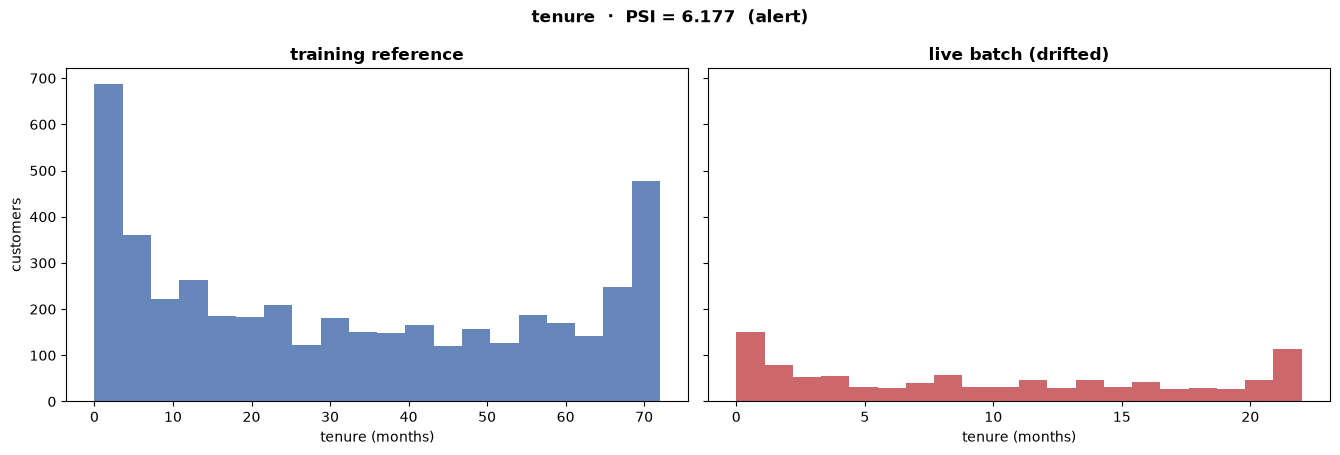

In [17]:
# The statistic, explained on one feature rather than trusted wholesale.
from churnml.pipeline import population_stability_index

ref, cur = X_train["tenure"], drifted["tenure"]
psi = population_stability_index(ref, cur)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)
for ax, series, title, colour in [(axes[0], ref, "training reference", "#4C72B0"), (axes[1], cur, "live batch (drifted)", "#C44E52")]:
    ax.hist(series, bins=20, color=colour, alpha=0.85)
    ax.set_title(title, weight="bold")
    ax.set_xlabel("tenure (months)")
axes[0].set_ylabel("customers")
axes[1].set_ylim(axes[0].get_ylim())
fig.suptitle(f"tenure  ·  PSI = {psi:.3f}  ({'alert' if psi >= 0.25 else 'ok'})", weight="bold")
plt.tight_layout()
fig.savefig(PATHS.figures / "10_drift_tenure.png", dpi=140, bbox_inches="tight")
plt.show()

In [18]:
# Does drift change the decision? Each perturbation is applied on its own and then
# all together, always with billing kept consistent, so the direction of every
# effect can be read off and checked against common sense.
variants = {
    "healthy batch": live,
    "tenure x0.3 only": campaign(live, contract=False, fiber=False, price=False),
    "all month-to-month only": campaign(live, tenure=False, fiber=False, price=False),
    "fiber for 400 customers only": campaign(live, tenure=False, contract=False, price=False),
    "MonthlyCharges x1.12 only": campaign(live, tenure=False, contract=False, fiber=False),
    "ALL together (the campaign)": drifted,
}
rows = []
for name, frame in variants.items():
    p = served.score(frame).churn_probability
    rows.append({"scenario": name, "mean predicted risk": p.mean(), "flagged": float((p >= served.threshold).mean())})
effects = pd.DataFrame(rows).set_index("scenario")
display(effects)

base_risk, base_flag = effects.loc["healthy batch"]
all_risk, all_flag = effects.loc["ALL together (the campaign)"]
direction_ok = effects.loc["tenure x0.3 only", "mean predicted risk"] > base_risk and effects.loc["all month-to-month only", "mean predicted risk"] > base_risk
display(Markdown(f"""
**Operational consequence, computed.** Mean predicted risk moves from **{base_risk:.3f} to {all_risk:.3f}**, and the share of customers flagged at
the threshold of {served.threshold:.2f} moves from **{base_flag:.1%} to {all_flag:.1%}**. A retention team staffed for the first list would
{"be handed a list " + f"{all_flag / base_flag:.1f}x as long" if all_flag > base_flag else "be handed a shorter list"}, and this is the signal that shows up on day three instead
of day thirty. The direction of each single perturbation is {"as expected (shorter tenure and month-to-month contracts both raise predicted risk)" if direction_ok else "NOT as expected, which would itself be a finding about the model"}.
"""))

,mean predicted risk,flagged
scenario,,
healthy batch,0.2559,0.3430
tenure x0.3 only,0.3508,0.4910
all month-to-month only,0.3016,0.4180
fiber for 400 customers only,0.2470,0.3290
MonthlyCharges x1.12 only,0.3276,0.4520
ALL together (the campaign),0.4933,0.6890



**Operational consequence, computed.** Mean predicted risk moves from **0.256 to 0.493**, and the share of customers flagged at
the threshold of 0.31 moves from **34.3% to 68.9%**. A retention team staffed for the first list would
be handed a list 2.0x as long, and this is the signal that shows up on day three instead
of day thirty. The direction of each single perturbation is as expected (shorter tenure and month-to-month contracts both raise predicted risk).


In [19]:
# What the data contract does to the INCONSISTENT version of the same campaign
# (tenure shortened, TotalCharges left alone): it cannot be scored by accident.
naive = campaign(live, consistent=False)
rep = churnml.validate_dataframe(naive, mode="serving", quarantine_bad=True)
inconsistent_rows = int(next(f.n_rows for f in rep.findings if f.check == "consistency.total_vs_tenure"))
try:
    served.score(naive)
    naive_outcome = "scored (the contract failed to catch it)"
except ValueError as exc:
    naive_outcome = "REFUSED by the serving contract"
q = served.score(naive, on_invalid="quarantine")

# What would have happened with NO contract? Call the model directly on the impossible
# records (bypassing the scorer on purpose) and compare with the consistent simulation.
bypass = served.model.predict_proba(naive[served.feature_columns])[:, 1]
bypass_risk, bypass_flag = float(bypass.mean()), float((bypass >= served.threshold).mean())
wrong_way = bypass_risk < base_risk
display(Markdown(f"""
**The inconsistent simulation.** Shortening tenure without touching `TotalCharges` produces **{inconsistent_rows:,} of {len(naive):,}** impossible records
(`TotalCharges / (tenure x MonthlyCharges)` outside the band seen in real data). Default policy: **{naive_outcome}**. With `on_invalid="quarantine"` the scorer
sets aside {len(q.quarantined):,} rows and scores the remaining {len(q)}.

For comparison, forcing those impossible records past the contract (calling the model directly) gives mean risk **{bypass_risk:.3f}** and a flag rate of **{bypass_flag:.1%}**,
against **{all_risk:.3f}** and **{all_flag:.1%}** for the consistent version of the same campaign and **{base_risk:.3f}** for the healthy batch.
{"The impossible records push predicted risk the WRONG way (down, although tenure fell and contracts moved to month-to-month): a model extrapolates confidently on inputs it has never seen, which is exactly why the contract refuses them." if wrong_way else "Here the impossible records happen to move risk in the same direction, but the numbers differ materially from the consistent simulation, so they would still be misleading."}
"""))


**The inconsistent simulation.** Shortening tenure without touching `TotalCharges` produces **896 of 1,000** impossible records
(`TotalCharges / (tenure x MonthlyCharges)` outside the band seen in real data). Default policy: **REFUSED by the serving contract**. With `on_invalid="quarantine"` the scorer
sets aside 896 rows and scores the remaining 104.

For comparison, forcing those impossible records past the contract (calling the model directly) gives mean risk **0.088** and a flag rate of **9.5%**,
against **0.493** and **68.9%** for the consistent version of the same campaign and **0.256** for the healthy batch.
The impossible records push predicted risk the WRONG way (down, although tenure fell and contracts moved to month-to-month): a model extrapolates confidently on inputs it has never seen, which is exactly why the contract refuses them.


---
## 7 · Rollback without retraining

The defining property of an artefact-based rollback is that it restores
**the exact bytes** that were working. A "rollback" that retrains produces a
different model, which is a redeployment, not a rollback.

The gate is a **floor, not a ranking**, so a version can clear it and still be
worse than what it replaces. To show that, we register the project's LightGBM
configuration (it clears the floor), promote it, observe that it is measurably
worse, and roll back. Rollback must return to the previously **promoted**
version, not merely the previous number in the registry: `v002` above was
registered but blocked, so it was never approved.

In [20]:
# Snapshot the approved model's scores BEFORE promoting anything. Capturing them
# after the promotion would compare the new model against itself.
approved_scores = churnml.load_active(versions_dir=PROD_VERSIONS).score(live_inputs).churn_probability

lgbm_model = CANDIDATES["lgbm"]
lgbm_val, lgbm_test = lgbm_model.predict_proba(X_val)[:, 1], lgbm_model.predict_proba(X_test)[:, 1]
lgbm_t = ev.optimal_threshold(ev.threshold_sweep(y_val, lgbm_val, **ECON))       # its own validation-optimal threshold
lgbm_scorer = ChurnScorer(lgbm_model, threshold=lgbm_t, model_version=next_version(PROD_VERSIONS), training_reference=X_train)
lg_sel = ev.metric_report(y_val, lgbm_val, threshold=lgbm_t)
lg_test = ev.metric_report(y_test, lgbm_test, threshold=lgbm_t)
successor = churnml.register_model(
    lgbm_scorer, model_key="lgbm", model_family="boosting",
    metrics={k: lg_sel[k] for k in ("roc_auc", "pr_auc", "f1", "brier", "accuracy")},
    test_metrics={k: lg_test[k] for k in ("roc_auc", "pr_auc", "f1", "brier", "accuracy")}, gate=GATE,
    data_path=PATHS.raw_csv, n_train=len(X_train), n_val=len(X_val), n_test=len(X_test), seed=SEED, threshold=lgbm_t,
    notes="Passes the quality floor but is worse than the approved model; used to demonstrate rollback.", versions_dir=PROD_VERSIONS)
churnml.promote(successor.version, versions_dir=PROD_VERSIONS, gate=GATE)                 # clears the floor, so it is allowed

m_old, m_new = registered.load_manifest(), successor.load_manifest()
compare = pd.DataFrame({
    f"{registered.version} ({m_old['model_key']})": {**m_old["metrics"], "test roc_auc": m_old["test_metrics"]["roc_auc"]},
    f"{successor.version} ({m_new['model_key']})": {**m_new["metrics"], "test roc_auc": m_new["test_metrics"]["roc_auc"]},
}).loc[["roc_auc", "pr_auc", "brier", "test roc_auc"]]
display(compare)
d = ev.paired_bootstrap_delta(y_val, p_val, lgbm_val, metric="roc_auc")
worse_scores = churnml.load_active(versions_dir=PROD_VERSIONS).score(live_inputs).churn_probability
print(f"The successor cleared the gate, yet the approved model is better by {d['delta']:+.4f} ROC-AUC on validation "
      f"(95% interval [{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]; {'excludes' if d['significant'] else 'includes'} zero).")
print(f"Traffic is now on {successor.version}: mean risk {worse_scores.mean():.4f} vs {approved_scores.mean():.4f}. Nothing alerts automatically,")
print("which is why the next cell rolls it back by hand.")

,v001 (logreg),v003 (lgbm)
roc_auc,0.8507,0.8249
pr_auc,0.6755,0.6271
brier,0.1320,0.1469
test roc_auc,0.8480,0.8302


The successor cleared the gate, yet the approved model is better by +0.0258 ROC-AUC on validation (95% interval [+0.0113, +0.0411]; excludes zero).
Traffic is now on v003: mean risk 0.2566 vs 0.2562. Nothing alerts automatically,
which is why the next cell rolls it back by hand.


In [21]:
target = churnml.rollback(current=successor.version, versions_dir=PROD_VERSIONS)
restored = churnml.load_active(versions_dir=PROD_VERSIONS)
scores_after = restored.score(live_inputs).churn_probability

print(f"rolled back to : {target}   (v002 was registered but never approved, so it is correctly skipped)")
assert target == registered.version
# Exact equality, not approximate: a rollback restores bytes, and a model that
# merely scores similarly is a different model.
np.testing.assert_allclose(approved_scores, scores_after, rtol=0, atol=0)
print("restored scores match the approved model exactly")
print(f"  max abs difference vs approved : {np.abs(approved_scores - scores_after).max():.2e}")
print(f"  max abs difference vs the successor : {np.abs(worse_scores - scores_after).max():.4f}")
print(f"  active.joblib checksum == recorded v001 bundle checksum : {sha256_file(PROD_VERSIONS / 'active.joblib') == registered.load_manifest()['bundle_sha256']}")
print("\nRollback is a registry write. No retraining, no code change, no rebuild.")

rolled back to : v001   (v002 was registered but never approved, so it is correctly skipped)
restored scores match the approved model exactly
  max abs difference vs approved : 0.00e+00
  max abs difference vs the successor : 0.5281
  active.joblib checksum == recorded v001 bundle checksum : True

Rollback is a registry write. No retraining, no code change, no rebuild.


In [22]:
# The audit trail: every promotion and rollback, and every version's fate.
log = pd.DataFrame(churnml.promotion_log(PROD_VERSIONS))
log["bundle_sha256"] = log["bundle_sha256"].str[:10]
display(log[["utc", "event", "version", "gate_passed", "forced", "reason", "bundle_sha256"]])

promoted = set(log["version"])
manifests = {r.version: r.load_manifest() for r in churnml.list_versions(PROD_VERSIONS)}
active_now = (PROD_VERSIONS / "active.version").read_text(encoding="utf-8")
registry_view = pd.DataFrame([
    {"version": v, "model": m["model_key"], "val roc_auc": m["metrics"]["roc_auc"],
     "gate passed": m["gate"].get("passed"), "ever promoted": v in promoted, "active now": v == active_now}
    for v, m in manifests.items()
]).set_index("version")
display(registry_view)

,utc,event,version,gate_passed,forced,reason,bundle_sha256
0,2026-10-05T22:05:54+00:00,promote,v001,True,False,,8678161080
1,2026-10-05T22:05:56+00:00,promote,v003,True,False,,9c64958530
2,2026-10-05T22:05:59+00:00,rollback,v001,None,False,rolled back from v003,8678161080


,model,val roc_auc,gate passed,ever promoted,active now
version,,,,,
v001,logreg,0.8507,True,True,True
v002,logreg_150rows,0.7577,False,False,False
v003,lgbm,0.8249,True,True,False


---
## 8 · The tests are the safety net

Everything above is demonstrated interactively once. The tests are what keep it
true next month, after someone edits a transformer. They assert **behaviour that
would silently corrupt results**: leakage, identifier leakage, split skew, monitor
sensitivity, a gate that must block, a scorer that must refuse, a rollback that
must skip an unapproved version, a latency benchmark that must score the rows it
reports.

In [23]:
import re
import subprocess
import sys as _sys

run = subprocess.run(
    [_sys.executable, "-W", "ignore", "-m", "pytest", "tests", "-o", "addopts=", "-q", "--tb=short",
     "-p", "no:cacheprovider", "--no-header", "--color=no"],
    cwd=str(ROOT), capture_output=True, text=True,
)
tail = [line for line in run.stdout.strip().splitlines() if line.strip()][-3:]
print("\n".join(tail))
print(f"\nexit code: {run.returncode}")
m = re.search(r"(\d+) passed", run.stdout)
n_passed = int(m.group(1)) if m else 0
n_failed = int(re.search(r"(\d+) failed", run.stdout).group(1)) if re.search(r"(\d+) failed", run.stdout) else 0
tests_ok = run.returncode == 0

................................................................         [100%]
64 passed in 12.40s

exit code: 0


---
## 9 · Conclusions

Assembled by code from the results above, so each statement is tied to the
output that supports it.

In [24]:
true_now = [
    f"A malformed batch is **not scored silently**: the serving contract refused or quarantined every one of the {int((refusals['default policy'] == 'refused').sum())} bad-input scenarios tried, "
    f"and scored the unlabelled traffic that is genuinely valid (§5).",
    f"Preprocessing **travels with the model** and the registered object is the whole bundle (model, threshold {served.threshold:.2f}, temperature {served.temperature:.2f}, column contract, drift profile). "
    f"Serving loaded it back from the registry and it reproduced the in-memory scores exactly (§4-§5).",
    f"The gate **blocks** a real version: {weak_registered.version} (ROC-AUC {weak_val['roc_auc']:.3f}) was refused while {registered.version} stayed active (§4).",
    f"Every promotion is checksum-verified and logged ({len(log)} entries); a corrupted or swapped bundle is refused at load.",
    f"Rollback restored **the exact bytes** of the previously *promoted* version (max abs score difference {np.abs(approved_scores - scores_after).max():.1e}) and skipped the never-approved {weak_registered.version} (§7).",
    f"The latency benchmark scores exactly the rows it reports: a {int(bench.rows.iloc[0]):,}-row batch takes {bench.median_ms.iloc[0]:.0f} ms (fixed overhead, mostly contract validation, dominates) "
    f"and a {int(bench.rows.iloc[-1]):,}-row batch {bench.median_ms.iloc[-1]:.0f} ms, i.e. {bench.us_per_row.iloc[-1]:.1f} µs/row, with validation included (§5).",
    f"On internally consistent simulated drift the monitor alerted on {alerted} and stayed quiet on the healthy batch; "
    f"flagged customers moved from {base_flag:.1%} to {all_flag:.1%} (§6). The inconsistent variant of the same simulation is caught by the data contract ({inconsistent_rows:,} impossible records).",
    f"Probabilities: validation ECE {manifest['metrics']['ece']:.3f}, held-out ECE {manifest['test_metrics']['ece']:.3f}; temperature scaling is {'a no-op (T = 1.00: already well scaled)' if abs(TEMPERATURE - 1.0) < 1e-9 else f'applied inside score() (T = {TEMPERATURE:.2f})'}.",
    f"The test suite: **{n_passed} passed, {n_failed} failed** ({'all green' if tests_ok else 'FAILING: see §8'}).",
]
display(Markdown("### What is now true of this model\n\n" + "\n".join(f"- {t}" for t in true_now)))

### What is now true of this model

- A malformed batch is **not scored silently**: the serving contract refused or quarantined every one of the 7 bad-input scenarios tried, and scored the unlabelled traffic that is genuinely valid (§5).
- Preprocessing **travels with the model** and the registered object is the whole bundle (model, threshold 0.31, temperature 1.00, column contract, drift profile). Serving loaded it back from the registry and it reproduced the in-memory scores exactly (§4-§5).
- The gate **blocks** a real version: v002 (ROC-AUC 0.758) was refused while v001 stayed active (§4).
- Every promotion is checksum-verified and logged (3 entries); a corrupted or swapped bundle is refused at load.
- Rollback restored **the exact bytes** of the previously *promoted* version (max abs score difference 0.0e+00) and skipped the never-approved v002 (§7).
- The latency benchmark scores exactly the rows it reports: a 100-row batch takes 14 ms (fixed overhead, mostly contract validation, dominates) and a 50,000-row batch 157 ms, i.e. 3.1 µs/row, with validation included (§5).
- On internally consistent simulated drift the monitor alerted on ['tenure', 'TotalCharges', 'MonthlyCharges', 'Contract'] and stayed quiet on the healthy batch; flagged customers moved from 34.3% to 68.9% (§6). The inconsistent variant of the same simulation is caught by the data contract (896 impossible records).
- Probabilities: validation ECE 0.031, held-out ECE 0.022; temperature scaling is a no-op (T = 1.00: already well scaled).
- The test suite: **64 passed, 0 failed** (all green).

### What is still missing before this could face real traffic

1. **A real serving surface.** No HTTP endpoint, auth, rate limiting, timeouts or
   retry policy. `score()` is a function call, not a service.
2. **Streaming monitoring.** Everything here scores a batch. Per-batch drift on a
   queue means reacting to *one bad day*, not one bad quarter. Feature drift also
   cannot see a change in the *relationship* between features and churn; that needs
   labels, which arrive weeks later.
3. **Feature freshness and point-in-time correctness.** The largest source of silent
   offline/online skew, and entirely absent here.
4. **A recalibration schedule.** Temperature is one constant from one fit; it decays
   as the population shifts. (Today it is 1.00, i.e. unused, which is the most
   favourable case.)
5. **Fairness.** `gender` and `SeniorCitizen` are model inputs. Whether they should
   be features, and whether flag rates differ across groups, is not examined.
6. **Roll-forward, not just rollback.** Who decides, on what online metric, that a
   new version is actually better? An offline floor cannot answer that.
7. **A shared, concurrent registry.** This registry is a local directory with a
   single writer; production needs locking, access control and retention policy.
8. **No experiment design.** A retention campaign scored by this model needs a
   randomised holdout to learn whether offers actually save customers. The
   `success_rate` assumed in notebook 01 is exactly the quantity an experiment would
   measure.

### The honest summary

Item 8 is the important one. Everything in this notebook makes the *model*
reliable and the *deployment* auditable. None of it establishes that acting on the
model *helps*, which needs a randomised holdout: a different kind of work entirely.